# Bài 2. Đánh giá YOLOv4 và YOLO26n trong bài toán phát hiện đối tượng

**Học viên:** Nguyễn Đăng Thới Toàn  
**MSHV:** 25C15062

## Câu hỏi nghiên cứu

Trên cùng một tập ảnh có nhãn, YOLOv4 và YOLO26n khác nhau thế nào về chất lượng phát hiện, tốc độ suy luận và khả năng chịu các điều kiện hình ảnh bất lợi?

Bài thực hành sử dụng trọng số COCO công bố sẵn của hai mô hình, **không huấn luyện lại**. Tất cả bảng, biểu đồ và ảnh minh họa được tạo trực tiếp trong notebook sau khi chạy. Kết quả trong bài là kết quả đo trên máy thực hiện; không sử dụng số liệu của nhà sản xuất để thay thế phép đo này.

**Giả thuyết:** YOLO26n có lợi thế tốc độ nhờ kích thước nano; độ chính xác và mức suy giảm dưới nhiễu cần được đo trước khi kết luận.

## 1. Môi trường và quy ước thực nghiệm

Chạy notebook bằng kernel của môi trường ảo có **PyTorch CUDA**, CUDA Toolkit (`nvcc`) và các gói sau. Cài gói trong terminal của môi trường ảo trước khi mở kernel:

```bash
python -m pip install -U ultralytics pycocotools opencv-python matplotlib pandas ipykernel imageio-ffmpeg
```

PyTorch bản CUDA nên được cài theo [hướng dẫn chính thức](https://pytorch.org/get-started/locally/) phù hợp driver và GPU. Notebook chỉ bỏ qua bước biên dịch nếu tìm thấy dấu xác nhận của chính lần build GPU trước đó trên cùng kiến trúc; lần đầu cần `nvcc`. Darknet cũ có thể cần điều chỉnh để biên dịch với CUDA Toolkit/GPU mới; lỗi biên dịch phải được xử lý trước khi đánh giá, không thay bằng bản CPU.

- **Tập kiểm thử:** COCO 2017 validation. Đánh giá chất lượng trên toàn bộ 5.000 ảnh COCO val2017 (`MAX_IMAGES = None`). Các thí nghiệm ảnh tối/che khuất dùng 60 ảnh được lấy mẫu bằng seed cố định; đo tốc độ dùng 50 ảnh. mAP@0.5 trên ảnh sạch do COCOeval tính từ đủ tập validation.
- **Đầu vào:** 608 × 608; YOLOv4 dùng phép resize của Darknet, YOLO26n dùng letterbox của Ultralytics. Cùng kích thước danh nghĩa nhưng cách tiền xử lý khác nhau.
- **Hậu xử lý:** ngưỡng confidence 0,001 cho AP; NMS IoU 0,45; tối đa 100 box/ảnh. Precision/Recall điểm hoạt động dùng confidence 0,25, IoU khớp 0,5.
- **Thiết bị:** GPU duy nhất, batch = 1, FP32 mặc định. Đo thời gian đầu cuối của hàm suy luận trên ảnh đã nạp vào RAM, gồm tiền xử lý và hậu xử lý; không gồm đọc tệp, tải trọng số hay vẽ hình.
- **Tính tái lập:** ghi phiên bản thư viện, GPU, mã nguồn Darknet và seed ở cuối bài. Hai mô hình dùng đúng cùng danh sách ảnh và nhãn COCO.

### Import thư viện và thiết lập đường dẫn

Cell tiếp theo tạo `ROOT`, `DATA`, `DARKNET` và các tham số dùng xuyên suốt bài. Hãy chạy cell này trước các cell dữ liệu và mô hình.


In [1]:
import ctypes as ct
import os
import random
import shutil
import subprocess
import sys
import tempfile
import time
import urllib.request
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.display import Video, display
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm import tqdm
from ultralytics import YOLO

ROOT = Path.cwd().resolve()
DATA = ROOT / "data_bai2"
DARKNET = ROOT / "darknet"
MAX_IMAGES = None  # dùng toàn bộ 5.000 ảnh COCO val2017
STRESS_IMAGES = 60  # cùng số ảnh cho mỗi phép biến dạng
SEED = 2026
IMG_SIZE = 608
NMS_IOU = 0.45
AP_CONF = 0.001
PR_CONF = 0.25
MAX_DET = 100
BENCH_IMAGES = 50
WARMUP = 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), "Bài đo này yêu cầu PyTorch nhận GPU CUDA."
DATA.mkdir(exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda)
print("Ultralytics:", ultralytics.__version__)

GPU: NVIDIA GeForce RTX 5090
PyTorch: 2.7.0+cu128 | CUDA: 12.8
Ultralytics: 8.4.189


## 2. Dữ liệu COCO val2017

Tải ảnh và nhãn gốc từ bucket COCO qua HTTPS của Amazon S3. Hai mô hình đều được huấn luyện trước trên COCO; tập validation tách khỏi tập train của bộ dữ liệu. Toàn bộ 5.000 ảnh validation được sử dụng cho đánh giá ảnh sạch; seed chỉ dùng khi chọn nhóm ảnh cho thí nghiệm điều kiện bất lợi. Lần chạy đầu cần khoảng 1 GB để tải ảnh và thêm dung lượng để giải nén.

In [2]:
def download_and_extract(url, archive_name, marker, expected_jpg_count=None):
    archive = DATA / archive_name
    complete = marker.exists()
    if expected_jpg_count is not None:
        complete &= len(list(marker.parent.glob("*.jpg"))) == expected_jpg_count
    if complete:
        print(f"Đã có dữ liệu: {marker.parent}")
        return

    if not archive.exists():
        print(f"Đang tải {archive_name}...")
        with tempfile.NamedTemporaryFile(dir=DATA, delete=False) as tmp:
            temporary = Path(tmp.name)
        try:
            with urllib.request.urlopen(url, timeout=60) as response:
                total = int(response.headers.get("Content-Length", 0))
                with (
                    temporary.open("wb") as output,
                    tqdm(
                        total=total or None,
                        unit="B",
                        unit_scale=True,
                        desc=archive_name,
                    ) as progress,
                ):
                    while chunk := response.read(4 * 1024 * 1024):
                        output.write(chunk)
                        progress.update(len(chunk))
                if total and progress.n != total:
                    raise RuntimeError(f"Tải chưa đủ: {progress.n}/{total} byte")
            temporary.replace(archive)
        finally:
            temporary.unlink(missing_ok=True)

    print(f"Đang giải nén {archive_name}...")
    try:
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(DATA)
    except zipfile.BadZipFile as exc:
        archive.unlink(missing_ok=True)
        raise RuntimeError("ZIP bị hỏng; chạy lại cell để tải lại.") from exc
    assert marker.exists(), f"Không tìm thấy {marker} sau khi giải nén"
    if expected_jpg_count is not None:
        actual = len(list(marker.parent.glob("*.jpg")))
        assert actual == expected_jpg_count, f"Thiếu ảnh: {actual}/{expected_jpg_count}"
    print(f"Đã chuẩn bị xong {archive_name}")


download_and_extract(
    "https://s3.amazonaws.com/images.cocodataset.org/zips/val2017.zip",
    "val2017.zip",
    DATA / "val2017" / "000000000139.jpg",
    expected_jpg_count=5000,
)
download_and_extract(
    "https://s3.amazonaws.com/images.cocodataset.org/annotations/annotations_trainval2017.zip",
    "annotations_trainval2017.zip",
    DATA / "annotations" / "instances_val2017.json",
)

coco = COCO(str(DATA / "annotations" / "instances_val2017.json"))
all_ids = sorted(coco.getImgIds())
rng = np.random.default_rng(SEED)
image_ids = (
    sorted(rng.choice(all_ids, size=MAX_IMAGES, replace=False).tolist())
    if MAX_IMAGES
    else all_ids
)
assert len(image_ids) > 0
print(f"Số ảnh đánh giá: {len(image_ids)} / {len(all_ids)}")
print("Ví dụ ID:", image_ids[:8])

Đã có dữ liệu: /workspace/workspace/lt/data_bai2/val2017
Đã có dữ liệu: /workspace/workspace/lt/data_bai2/annotations
loading annotations into memory...
Done (t=0.30s)
creating index...
index created!
Số ảnh đánh giá: 5000 / 5000
Ví dụ ID: [139, 285, 632, 724, 776, 785, 802, 872]


## 3. Nạp hai mô hình đã huấn luyện

YOLOv4 chạy qua thư viện `libdarknet.so` của [AlexeyAB/darknet](https://github.com/AlexeyAB/darknet) biên dịch với `GPU=1`; YOLO26n dùng trọng số `yolo26n.pt` trong [Ultralytics](https://docs.ultralytics.com/models/yolo26/). Notebook sẽ tải trọng số YOLOv4 nếu chưa có. Khi biên dịch Darknet, mã sử dụng compute capability do PyTorch báo cho GPU hiện tại; CUDA Toolkit phải hỗ trợ kiến trúc đó.

In [3]:
if not (DARKNET / "Makefile").exists():
    subprocess.run(
        ["git", "clone", "https://github.com/AlexeyAB/darknet.git", str(DARKNET)],
        check=True,
    )

cuda_bin = Path("/usr/local/cuda/bin")
if cuda_bin.is_dir() and str(cuda_bin) not in os.environ["PATH"].split(os.pathsep):
    os.environ["PATH"] = str(cuda_bin) + os.pathsep + os.environ["PATH"]


def run_darknet_build(command):
    result = subprocess.run(
        command,
        cwd=DARKNET,
        check=False,
        text=True,
        errors="replace",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
    )
    if result.returncode:
        raise RuntimeError(
            f"Biên dịch Darknet thất bại (mã {result.returncode}):\n"
            + result.stdout[-12000:]
        )


libdarknet = DARKNET / "libdarknet.so"
major, minor = torch.cuda.get_device_capability(0)
sm = f"{major}{minor}"
gpu_build_stamp = DARKNET / ".bai2_gpu_build"
needs_build = (
    not libdarknet.exists()
    or not gpu_build_stamp.exists()
    or gpu_build_stamp.read_text().strip() != sm
)
if needs_build:
    assert shutil.which("nvcc"), (
        "Không tìm thấy nvcc. Hãy cài CUDA Toolkit gồm nvcc và các thư viện "
        "phát triển CUDA, rồi chạy lại cell này. PyTorch CUDA không kèm nvcc."
    )
    arch = f"-gencode arch=compute_{sm},code=sm_{sm}"
    run_darknet_build(["make", "clean"])
    run_darknet_build(["make", "-j4", "GPU=1", "CUDNN=0", "LIBSO=1", f"ARCH={arch}"])
    gpu_build_stamp.write_text(sm)
    print("Đã biên dịch Darknet cho GPU.")
assert libdarknet.exists(), "Chưa tạo được libdarknet.so"

weights = DARKNET / "yolov4.weights"
if not weights.exists() or weights.stat().st_size != 257_717_640:
    url = "https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v4_pre/yolov4.weights"
    with tempfile.NamedTemporaryFile(dir=DARKNET, delete=False) as tmp:
        temporary = Path(tmp.name)
    try:
        urllib.request.urlretrieve(url, temporary)
        assert temporary.stat().st_size == 257_717_640, (
            "Tệp trọng số YOLOv4 chưa đầy đủ"
        )
        temporary.replace(weights)
    finally:
        temporary.unlink(missing_ok=True)

sys.path.insert(0, str(DARKNET))
import darknet


def load_darknet_quietly():
    # Darknet là thư viện C; chuyển stdout/stderr sang tệp tạm trong lúc nạp.
    with tempfile.TemporaryFile(mode="w+b") as captured:
        saved_stdout, saved_stderr = os.dup(1), os.dup(2)
        libc = ct.CDLL(None)
        libc.fflush.argtypes = [ct.c_void_p]
        try:
            libc.fflush(None)
            os.dup2(captured.fileno(), 1)
            os.dup2(captured.fileno(), 2)
            try:
                return darknet.load_network(
                    str(DARKNET / "cfg" / "yolov4.cfg"),
                    str(DARKNET / "cfg" / "coco.data"),
                    str(weights),
                )
            except BaseException as exc:
                libc.fflush(None)
                captured.seek(0)
                details = captured.read().decode("utf-8", errors="replace")
                raise RuntimeError(
                    "Không nạp được YOLOv4; log cuối:\n" + details[-12000:]
                ) from exc
        finally:
            libc.fflush(None)
            os.dup2(saved_stdout, 1)
            os.dup2(saved_stderr, 2)
            os.close(saved_stdout)
            os.close(saved_stderr)


original_cwd = Path.cwd()
try:
    os.chdir(DARKNET)  # coco.data dùng đường dẫn tương đối data/coco.names
    network, darknet_names, _ = load_darknet_quietly()
finally:
    os.chdir(original_cwd)
assert darknet.network_width(network) == darknet.network_height(network) == IMG_SIZE
model26 = YOLO("yolo26n.pt")
model26.to("cuda:0")
assert len(darknet_names) == len(model26.names) == 80
print("Đã nạp YOLOv4 và YOLO26n trên GPU")

Đã nạp YOLOv4 và YOLO26n trên GPU


### Chuẩn hóa lớp và bounding box

Hai thư viện trả dự đoán theo định dạng khác nhau. Mỗi hàm bên dưới chuyển kết quả thành `{class_id, score, xyxy}` ở hệ tọa độ của ảnh gốc. Ánh xạ 80 lớp COCO liên tục sang ID danh mục COCO gốc được kiểm tra trước khi tính chỉ số. Darknet wrapper mặc định làm tròn score; vì vậy phần phát hiện YOLOv4 ở đây gọi API thấp hơn để giữ score dạng số thực đầy đủ.

In [4]:
COCO80_TO_ID = [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    27,
    28,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    46,
    47,
    48,
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    67,
    70,
    72,
    73,
    74,
    75,
    76,
    77,
    78,
    79,
    80,
    81,
    82,
    84,
    85,
    86,
    87,
    88,
    89,
    90,
]
assert len(COCO80_TO_ID) == 80
assert COCO80_TO_ID == coco.getCatIds(), "Thứ tự category COCO không khớp"
assert darknet_names[0] == "person" and model26.names[0] == "person"
assert darknet_names[2] == "car" and model26.names[2] == "car"
assert darknet_names[-1] == "toothbrush" and model26.names[79] == "toothbrush"


def read_image(image_id):
    info = coco.loadImgs(image_id)[0]
    image = cv2.imread(str(DATA / "val2017" / info["file_name"]))
    if image is None:
        raise FileNotFoundError(info["file_name"])
    return image


def infer_yolov4(image):
    height, width = image.shape[:2]
    resized = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    dark_image = darknet.make_image(IMG_SIZE, IMG_SIZE, 3)
    try:
        darknet.copy_image_from_bytes(dark_image, rgb.tobytes())
        count = ct.pointer(ct.c_int(0))
        darknet.predict_image(network, dark_image)
        raw = darknet.get_network_boxes(
            network, IMG_SIZE, IMG_SIZE, AP_CONF, 0.5, None, 0, count, 0
        )
        try:
            darknet.do_nms_sort(raw, count[0], 80, NMS_IOU)
            detections = []
            for i in range(count[0]):
                box = raw[i].bbox
                x1 = (box.x - box.w / 2) * width / IMG_SIZE
                y1 = (box.y - box.h / 2) * height / IMG_SIZE
                x2 = (box.x + box.w / 2) * width / IMG_SIZE
                y2 = (box.y + box.h / 2) * height / IMG_SIZE
                for cls in range(80):
                    score = float(raw[i].prob[cls])
                    if score >= AP_CONF:
                        detections.append((cls, score, (x1, y1, x2, y2)))
        finally:
            darknet.free_detections(raw, count[0])
    finally:
        darknet.free_image(dark_image)
    return sorted(detections, key=lambda item: item[1], reverse=True)[:MAX_DET]


def infer_yolo26n(image):
    result = model26.predict(
        image,
        imgsz=IMG_SIZE,
        device=0,
        conf=AP_CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        quantize=32,
        verbose=False,
    )[0]
    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        return []
    xyxy = boxes.xyxy.cpu().numpy()
    scores = boxes.conf.cpu().numpy()
    classes = boxes.cls.cpu().numpy().astype(int)
    return [
        (int(cls), float(score), tuple(map(float, box)))
        for cls, score, box in zip(classes, scores, xyxy)
    ]


INFER = {"YOLOv4": infer_yolov4, "YOLO26n": infer_yolo26n}
print("Ánh xạ lớp và định dạng dự đoán đã sẵn sàng")

Ánh xạ lớp và định dạng dự đoán đã sẵn sàng


## 4. Giao thức đánh giá

**mAP@0.5** tính bằng `pycocotools.COCOeval` trên toàn bộ 80 lớp, IoU = 0,5, tối đa 100 dự đoán mỗi ảnh. **Precision/Recall** là micro-average tại score ≥ 0,25: ghép một dự đoán với tối đa một nhãn thật cùng lớp nếu IoU ≥ 0,5; vùng `iscrowd` không được tính như một false positive. Vì cách tổng hợp khác nhau, Precision/Recall ở một ngưỡng score không thể suy ra trực tiếp từ mAP.

Điều kiện ánh sáng yếu và che khuất là ảnh biến đổi **nhân tạo**, giữ nguyên nhãn. Phần che khuất đặt hình chữ nhật lên giữa vật thể lớn nhất của mỗi ảnh; cách này kiểm tra mức suy giảm do che một phần chứ không mô phỏng mọi tình huống thực tế. Nhóm “nhiều vật thể nhỏ” được lấy mẫu cố định từ các ảnh có ít nhất ba nhãn với diện tích gốc nhỏ hơn 32² pixel; cột `AP50_small` chỉ đánh giá các vật thể nhỏ theo chuẩn diện tích COCO.

In [5]:
def clip_xyxy(box, width, height):
    x1, y1, x2, y2 = box
    return (
        max(0.0, min(float(x1), width)),
        max(0.0, min(float(y1), height)),
        max(0.0, min(float(x2), width)),
        max(0.0, min(float(y2), height)),
    )


def to_coco_results(image_id, detections, image):
    height, width = image.shape[:2]
    rows = []
    for cls, score, box in detections:
        x1, y1, x2, y2 = clip_xyxy(box, width, height)
        if x2 <= x1 or y2 <= y1:
            continue
        rows.append(
            {
                "image_id": int(image_id),
                "category_id": COCO80_TO_ID[cls],
                "bbox": [x1, y1, x2 - x1, y2 - y1],
                "score": score,
            }
        )
    return rows


def bbox_iou(a, b):
    xx1, yy1 = max(a[0], b[0]), max(a[1], b[1])
    xx2, yy2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, xx2 - xx1) * max(0, yy2 - yy1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    return intersection / (area_a + area_b - intersection + 1e-12)


def xywh_to_xyxy(box):
    x, y, w, h = box
    return (x, y, x + w, y + h)


def count_matches(image_id, detections):
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)]))
    ordinary = [ann for ann in anns if not ann.get("iscrowd", 0)]
    crowd = [ann for ann in anns if ann.get("iscrowd", 0)]
    matched = set()
    tp = fp = 0
    for cls, score, box in sorted(detections, key=lambda p: p[1], reverse=True):
        if score < PR_CONF:
            continue
        cat_id = COCO80_TO_ID[cls]
        candidates = [
            (bbox_iou(box, xywh_to_xyxy(ann["bbox"])), idx)
            for idx, ann in enumerate(ordinary)
            if idx not in matched and ann["category_id"] == cat_id
        ]
        best_iou, best_idx = max(candidates, default=(0, -1))
        if best_iou >= 0.5:
            matched.add(best_idx)
            tp += 1
        elif not any(
            ann["category_id"] == cat_id
            and bbox_iou(box, xywh_to_xyxy(ann["bbox"])) >= 0.5
            for ann in crowd
        ):
            fp += 1
    return tp, fp, len(ordinary) - tp


def ap_metrics(image_ids_for_case, result_rows):
    if not result_rows:
        return 0.0, 0.0
    result_coco = coco.loadRes(result_rows)
    evaluator = COCOeval(coco, result_coco, "bbox")
    evaluator.params.imgIds = list(map(int, image_ids_for_case))
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()
    ap50 = float(evaluator.stats[1])
    precision = evaluator.eval["precision"][0, :, :, 1, 2]
    valid = precision[precision >= 0]
    ap50_small = float(valid.mean()) if valid.size else float("nan")
    return ap50, ap50_small

### Tạo các điều kiện và chạy hai mô hình trên cùng ảnh

`clean_stress` là nhóm ảnh sạch dùng làm mốc riêng cho điều kiện ánh sáng yếu và che khuất. Nhờ vậy, mức suy giảm không bị nhầm với khác biệt do chọn ảnh. Mỗi kết quả dùng cùng một tập nhãn COCO gốc; không dùng nhãn sinh từ mô hình.

In [6]:
def low_light(image):
    return np.clip(image.astype(np.float32) * 0.35, 0, 255).astype(np.uint8)


def occlude(image, image_id):
    altered = image.copy()
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)], iscrowd=False))
    if not anns:
        return altered
    target = max(anns, key=lambda ann: ann["area"])
    x, y, width, height = target["bbox"]
    cx, cy = x + width / 2, y + height / 2
    half_w, half_h = 0.28 * width, 0.28 * height
    x1, y1, x2, y2 = clip_xyxy(
        (cx - half_w, cy - half_h, cx + half_w, cy + half_h),
        altered.shape[1],
        altered.shape[0],
    )
    cv2.rectangle(
        altered, (int(x1), int(y1)), (int(x2), int(y2)), (40, 40, 40), thickness=-1
    )
    return altered


def small_count(image_id):
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[int(image_id)], iscrowd=False))
    return sum(ann["area"] < 32**2 for ann in anns)


stress_candidates = [
    image_id
    for image_id in image_ids
    if coco.getAnnIds(imgIds=[int(image_id)], iscrowd=False)
]
small_candidates = [image_id for image_id in image_ids if small_count(image_id) >= 3]
stress_ids = sorted(
    np.random.default_rng(SEED + 1)
    .choice(
        stress_candidates,
        size=min(STRESS_IMAGES, len(stress_candidates)),
        replace=False,
    )
    .tolist()
)
small_ids = sorted(
    np.random.default_rng(SEED + 2)
    .choice(
        small_candidates, size=min(STRESS_IMAGES, len(small_candidates)), replace=False
    )
    .tolist()
)
assert stress_ids and small_ids, "Hãy tăng MAX_IMAGES để có đủ ảnh nhiều vật thể nhỏ"
CASES = {
    "Ảnh sạch": (image_ids, lambda image, image_id: image),
    "Sạch / nhóm stress": (stress_ids, lambda image, image_id: image),
    "Ánh sáng yếu": (stress_ids, lambda image, image_id: low_light(image)),
    "Che khuất": (stress_ids, occlude),
    "Nhiều vật thể nhỏ": (small_ids, lambda image, image_id: image),
}
print({name: len(ids) for name, (ids, _) in CASES.items()})

{'Ảnh sạch': 5000, 'Sạch / nhóm stress': 60, 'Ánh sáng yếu': 60, 'Che khuất': 60, 'Nhiều vật thể nhỏ': 60}


In [7]:
records = []
all_predictions = {}
for case_name, (case_ids, transform) in CASES.items():
    for model_name, infer in INFER.items():
        result_rows = []
        tp = fp = fn = 0
        prediction_cache = {}
        for position, image_id in enumerate(case_ids, start=1):
            image = transform(read_image(image_id), image_id)
            if case_name in ("Sạch / nhóm stress", "Nhiều vật thể nhỏ"):
                detections = all_predictions[("Ảnh sạch", model_name)][image_id]
            else:
                detections = infer(image)
            prediction_cache[image_id] = detections
            result_rows.extend(to_coco_results(image_id, detections, image))
            a, b, c = count_matches(image_id, detections)
            tp, fp, fn = tp + a, fp + b, fn + c
            if position % 500 == 0 or position == len(case_ids):
                print(f"{case_name} / {model_name}: {position}/{len(case_ids)} ảnh")
        ap50, ap50_small = ap_metrics(case_ids, result_rows)
        records.append(
            {
                "Điều kiện": case_name,
                "Mô hình": model_name,
                "Số ảnh": len(case_ids),
                "mAP@0.5": ap50,
                "AP50_small": ap50_small,
                "Precision@0.25": tp / max(tp + fp, 1),
                "Recall@0.25": tp / max(tp + fn, 1),
            }
        )
        all_predictions[(case_name, model_name)] = prediction_cache
        print(f"Xong: {case_name} / {model_name}")

quality = pd.DataFrame(records)
display(quality.round(4))

Ảnh sạch / YOLOv4: 500/5000 ảnh
Ảnh sạch / YOLOv4: 1000/5000 ảnh
Ảnh sạch / YOLOv4: 1500/5000 ảnh
Ảnh sạch / YOLOv4: 2000/5000 ảnh
Ảnh sạch / YOLOv4: 2500/5000 ảnh
Ảnh sạch / YOLOv4: 3000/5000 ảnh
Ảnh sạch / YOLOv4: 3500/5000 ảnh
Ảnh sạch / YOLOv4: 4000/5000 ảnh
Ảnh sạch / YOLOv4: 4500/5000 ảnh
Ảnh sạch / YOLOv4: 5000/5000 ảnh
Loading and preparing results...
DONE (t=0.85s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=15.89s).
Accumulating evaluation results...
DONE (t=3.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.504
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.748
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.557
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.356
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.559
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | 

,Điều kiện,Mô hình,Số ảnh,mAP@0.5,AP50_small,Precision@0.25,Recall@0.25
0,Ảnh sạch,YOLOv4,5000,0.7477,0.5930,0.7061,0.7134
1,Ảnh sạch,YOLO26n,5000,0.5554,0.3180,0.7800,0.4848
2,Sạch / nhóm stress,YOLOv4,60,0.7589,0.6488,0.6445,0.6610
3,Sạch / nhóm stress,YOLO26n,60,0.5808,0.4070,0.7926,0.4037
4,Ánh sáng yếu,YOLOv4,60,0.7520,0.6669,0.6703,0.6371
5,Ánh sáng yếu,YOLO26n,60,0.5664,0.4059,0.7766,0.3850
6,Che khuất,YOLOv4,60,0.5945,0.5998,0.5676,0.5724
7,Che khuất,YOLO26n,60,0.4488,0.3244,0.6856,0.3492
8,Nhiều vật thể nhỏ,YOLOv4,60,0.6987,0.6102,0.6277,0.6741
9,Nhiều vật thể nhỏ,YOLO26n,60,0.5173,0.4188,0.7778,0.3987


### Mức suy giảm chất lượng

Với mỗi điều kiện, lấy đúng nhóm ảnh sạch làm mốc. **Hiệu tuyệt đối** là `ΔmAP = mAP_sạch − mAP_biến_dạng` trên thang 0–1. **Mức thay đổi tương đối** là `ΔmAP / mAP_sạch × 100%`. Giá trị dương nghĩa là hiệu năng giảm; giá trị âm nghĩa là hiệu năng tăng. Nhóm chỉ có 60 ảnh nên các chênh lệch này chưa phản ánh độ bất định thống kê.


,Mô hình,Điều kiện,Giảm mAP@0.5 (Δ),Giảm tương đối (%)
0,YOLOv4,Ánh sáng yếu,0.01,0.91
1,YOLOv4,Che khuất,0.16,21.66
2,YOLO26n,Ánh sáng yếu,0.01,2.49
3,YOLO26n,Che khuất,0.13,22.74


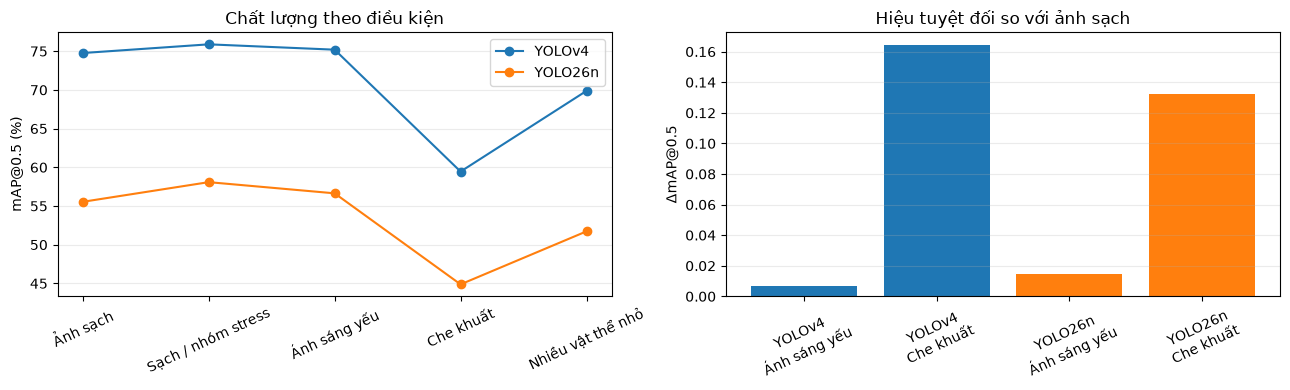

In [8]:
degradation = []
for model_name in INFER:
    reference = quality.query(
        '`Điều kiện` == "Sạch / nhóm stress" and `Mô hình` == @model_name'
    ).iloc[0]
    for condition in ("Ánh sáng yếu", "Che khuất"):
        target = quality.query(
            "`Điều kiện` == @condition and `Mô hình` == @model_name"
        ).iloc[0]
        delta = reference["mAP@0.5"] - target["mAP@0.5"]
        degradation.append(
            {
                "Mô hình": model_name,
                "Điều kiện": condition,
                "Giảm mAP@0.5 (Δ)": delta,
                "Giảm tương đối (%)": 100 * delta / max(reference["mAP@0.5"], 1e-12),
            }
        )
degradation = pd.DataFrame(degradation)
display(degradation.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model_name in INFER:
    subset = quality[quality["Mô hình"] == model_name]
    axes[0].plot(
        subset["Điều kiện"], 100 * subset["mAP@0.5"], marker="o", label=model_name
    )
    subset_deg = degradation[degradation["Mô hình"] == model_name]
    axes[1].bar(
        [f"{model_name}\n{v}" for v in subset_deg["Điều kiện"]],
        subset_deg["Giảm mAP@0.5 (Δ)"],
        label=model_name,
    )
axes[0].set(ylabel="mAP@0.5 (%)", title="Chất lượng theo điều kiện")
axes[1].set(ylabel="ΔmAP@0.5", title="Hiệu tuyệt đối so với ảnh sạch")
for axis in axes:
    axis.tick_params(axis="x", rotation=25)
    axis.grid(axis="y", alpha=0.25)
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Đo độ trễ và FPS trên GPU

Đo cùng các ảnh sạch đã chọn, lần lượt chạy từng mô hình; có warm-up để loại ảnh hưởng khởi tạo. Số `FPS = số ảnh / tổng thời gian suy luận`, batch = 1. Thời gian bao gồm chuyển dữ liệu lên/xuống GPU khi thư viện thực hiện. Tốc độ này phụ thuộc GPU, driver, CUDA, precision, phương thức tiền xử lý và batch size; không dùng để so sánh trực tiếp với bảng benchmark ở phần cứng khác.

In [9]:
benchmark_ids = image_ids[: min(BENCH_IMAGES, len(image_ids))]
benchmark_images = [read_image(image_id) for image_id in benchmark_ids]
speed_rows = []
for model_name, infer in INFER.items():
    for image in benchmark_images[: min(WARMUP, len(benchmark_images))]:
        infer(image)
    torch.cuda.synchronize()
    times_ms = []
    for image in benchmark_images:
        torch.cuda.synchronize()
        started = time.perf_counter()
        infer(image)
        torch.cuda.synchronize()
        times_ms.append(1000 * (time.perf_counter() - started))
    speed_rows.append(
        {
            "Mô hình": model_name,
            "Số ảnh": len(times_ms),
            "Latency TB (ms)": np.mean(times_ms),
            "Latency trung vị (ms)": np.median(times_ms),
            "Latency p95 (ms)": np.percentile(times_ms, 95),
            "FPS": 1000 * len(times_ms) / sum(times_ms),
        }
    )
speed = pd.DataFrame(speed_rows)
display(speed.round(2))

,Mô hình,Số ảnh,Latency TB (ms),Latency trung vị (ms),Latency p95 (ms),FPS
0,YOLOv4,50,15.51,13.43,31.43,64.46
1,YOLO26n,50,6.15,6.24,6.65,162.70


## 6. Minh họa dự đoán cạnh nhau

Cùng một ảnh hoặc khung hình được đưa vào cả hai mô hình. Có thể đặt `IMAGE_PATH` thành đường dẫn ảnh riêng; khi dùng ảnh riêng không có nhãn, kết quả chỉ để minh họa. Màu box theo lớp COCO, nhãn hiển thị score. Hình minh họa giúp nhận ra lỗi bỏ sót, nhầm lớp hoặc box lệch; kết luận định lượng dựa trên bảng có nhãn thật ở trên.

COCO image ID: 7511


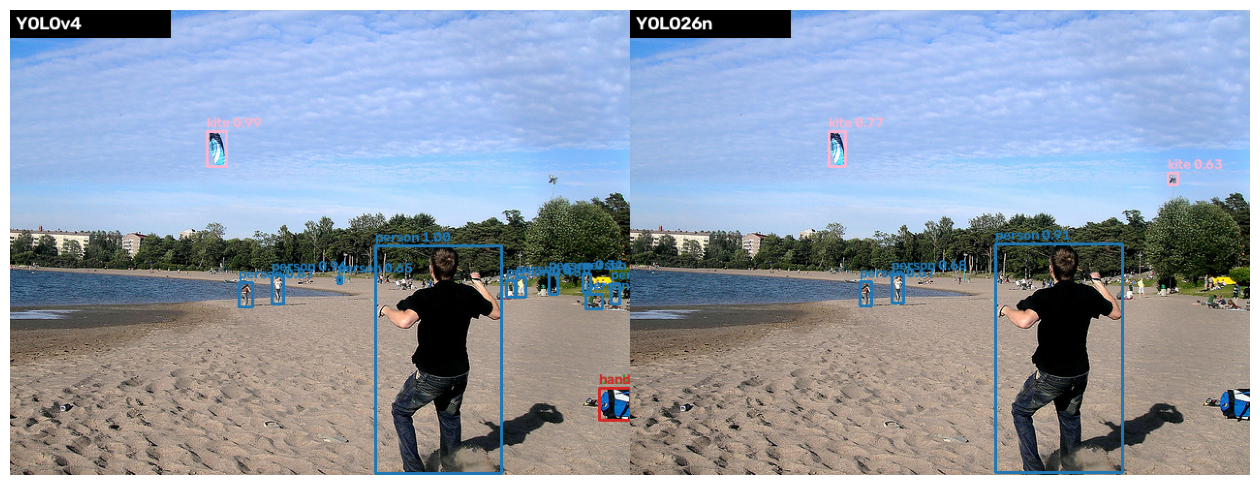

In [10]:
def draw_detections(image, detections, title, score_limit=PR_CONF):
    canvas = image.copy()
    height, width = canvas.shape[:2]
    for cls, score, box in detections:
        if score < score_limit:
            continue
        x1, y1, x2, y2 = map(int, clip_xyxy(box, width, height))
        color = tuple(int(255 * v) for v in plt.cm.tab20(cls % 20)[:3][::-1])
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
        label = f"{coco.cats[COCO80_TO_ID[cls]]['name']} {score:.2f}"
        cv2.putText(
            canvas,
            label,
            (x1, max(16, y1 - 4)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.48,
            color,
            2,
            cv2.LINE_AA,
        )
    cv2.rectangle(canvas, (0, 0), (min(width, 165), 28), (0, 0, 0), -1)
    cv2.putText(
        canvas,
        title,
        (6, 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.62,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    return canvas


def side_by_side(image, predictions):
    left = draw_detections(image, predictions["YOLOv4"], "YOLOv4")
    right = draw_detections(image, predictions["YOLO26n"], "YOLO26n")
    return np.concatenate([left, right], axis=1)


IMAGE_PATH = None  # Ví dụ: Path("anh_cua_toi.jpg")
if IMAGE_PATH is None:
    demo_image_id = small_ids[0]
    demo_image = read_image(demo_image_id)
    demo_predictions = {
        name: all_predictions[("Ảnh sạch", name)][demo_image_id] for name in INFER
    }
    print("COCO image ID:", demo_image_id)
else:
    demo_image = cv2.imread(str(IMAGE_PATH))
    if demo_image is None:
        raise FileNotFoundError(IMAGE_PATH)
    demo_predictions = {name: infer(demo_image) for name, infer in INFER.items()}
    print("Ảnh riêng:", IMAGE_PATH)
comparison = side_by_side(demo_image, demo_predictions)
plt.figure(figsize=(16, 7))
plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Demo video

`VIDEO_PATH` trỏ đến video riêng; nếu đặt `None`, notebook tạo đoạn demo từ ảnh COCO. Với video riêng, mặc định xử lý **5 giây đầu ở đúng FPS nguồn**; đặt `VIDEO_SECONDS = None` để xử lý toàn bộ video. Mỗi mô hình nhận cùng khung hình đã thu về 640 × 360, ghép cạnh nhau thành video 1280 × 360. Đầu ra dùng H.264 để phát trong trình duyệt, được nhúng vào notebook và lưu thành `so_sanh_yolo_h264.mp4` để mở riêng khi cần. Tốc độ phát video không phải FPS benchmark vì còn đọc, vẽ box và mã hóa.


In [11]:
import imageio_ffmpeg

VIDEO_PATH = ROOT / "14620692_1280_720_30fps.mp4"  # None: demo từ ảnh COCO
VIDEO_SECONDS = 5.0  # None: xử lý toàn bộ video
FRAME_SIZE = (640, 360)  # mỗi bên; đầu ra 1280 × 360, giữ tỷ lệ 16:9
OUTPUT_VIDEO = ROOT / "so_sanh_yolo_h264.mp4"

if VIDEO_PATH is None:
    source_fps = 4.0
    frame_limit = 12
    source_frames = (read_image(image_id) for image_id in image_ids[:frame_limit])
else:
    source = cv2.VideoCapture(str(VIDEO_PATH))
    if not source.isOpened():
        raise FileNotFoundError(f"Không mở được video: {VIDEO_PATH}")
    source_fps = source.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(source_fps) or source_fps <= 0:
        source.release()
        raise ValueError("Không đọc được FPS của video đầu vào")
    total_frames = int(source.get(cv2.CAP_PROP_FRAME_COUNT))
    requested_frames = (
        total_frames if VIDEO_SECONDS is None else round(source_fps * VIDEO_SECONDS)
    )
    frame_limit = (
        min(total_frames, requested_frames) if total_frames > 0 else requested_frames
    )

    def read_video_frames():
        try:
            for _ in range(frame_limit):
                ok, frame = source.read()
                if not ok:
                    break
                yield frame
        finally:
            source.release()

    source_frames = read_video_frames()

output_size = (FRAME_SIZE[0] * 2, FRAME_SIZE[1])
encoder = imageio_ffmpeg.write_frames(
    OUTPUT_VIDEO,
    size=output_size,
    fps=source_fps,
    codec="libx264",
    pix_fmt_in="rgb24",
    pix_fmt_out="yuv420p",
    macro_block_size=8,
    quality=7,
    ffmpeg_log_level="error",
    output_params=["-movflags", "+faststart"],
)
frame_count = 0
try:
    encoder.send(None)
    for frame in source_frames:
        resized = cv2.resize(frame, FRAME_SIZE, interpolation=cv2.INTER_AREA)
        predictions = {name: infer(resized) for name, infer in INFER.items()}
        side_image = side_by_side(resized, predictions)
        rgb_image = cv2.cvtColor(side_image, cv2.COLOR_BGR2RGB)
        encoder.send(rgb_image.tobytes())
        frame_count += 1
finally:
    encoder.close()
    if VIDEO_PATH is not None:
        source.release()

if frame_count == 0 or not OUTPUT_VIDEO.exists() or OUTPUT_VIDEO.stat().st_size == 0:
    raise RuntimeError("Không tạo được video đầu ra")
print(
    f"Đã xử lý {frame_count} khung hình ở {source_fps:.2f} FPS "
    f"({frame_count / source_fps:.1f} giây)."
)
print("Video H.264 đã lưu tại:", OUTPUT_VIDEO)
display(Video(str(OUTPUT_VIDEO), embed=True, html_attributes="controls"))

Đã xử lý 150 khung hình ở 29.97 FPS (5.0 giây).
Video H.264 đã lưu tại: /workspace/workspace/lt/so_sanh_yolo_h264.mp4


## 7. Nhận xét và giới hạn

Các ô dưới đây in ra nhận xét dựa trên chính số đo của lần chạy. Việc diễn giải cần xem cả mAP@0.5, Precision/Recall, độ trễ và ảnh minh họa; một mô hình có thể nhanh hơn nhưng bỏ sót vật thể nhỏ hoặc suy giảm mạnh hơn trong ảnh tối.

In [12]:
clean = quality[quality["Điều kiện"] == "Ảnh sạch"].set_index("Mô hình")
ap_scores = clean["mAP@0.5"].sort_values(ascending=False)
best_ap, other_ap = ap_scores.index[:2]
ap_gap = ap_scores.iloc[0] - ap_scores.iloc[1]
ap_relative_pct = 100 * ap_gap / ap_scores.iloc[1]
print(
    f"Trên {len(image_ids)} ảnh sạch, {best_ap} đạt mAP@0.5 = "
    f"{ap_scores.iloc[0]:.4f}, {other_ap} đạt {ap_scores.iloc[1]:.4f}; "
    f"hiệu tuyệt đối ΔmAP@0.5 = {ap_gap:.4f}. "
    f"{best_ap} cao hơn {ap_relative_pct:.1f}% tương đối so với {other_ap}."
)
fps_scores = speed.set_index("Mô hình")["FPS"].sort_values(ascending=False)
fastest, other_speed = fps_scores.index[:2]
print(
    f"Trong phép đo batch=1 trên GPU này, {fastest} đạt "
    f"{fps_scores.iloc[0]:.1f} FPS, {other_speed} đạt "
    f"{fps_scores.iloc[1]:.1f} FPS."
)
for model_name in INFER:
    subset = degradation[degradation["Mô hình"] == model_name]
    for row in subset.itertuples(index=False):
        direction = "giảm" if row[2] >= 0 else "tăng"
        print(
            f"{model_name}, {row[1]}: mAP@0.5 {direction} "
            f"{abs(row[2]):.4f}; thay đổi tương đối "
            f"{abs(row[3]):.1f}% so với cùng nhóm ảnh sạch."
        )
print(
    "mAP ảnh sạch dùng toàn bộ COCO val2017; kết quả ảnh biến dạng và tốc độ dựa trên các nhóm ảnh nhỏ hơn, cần lặp phép đo để đánh giá độ ổn định."
)

Trên 5000 ảnh sạch, YOLOv4 đạt mAP@0.5 = 0.7477, YOLO26n đạt 0.5554; hiệu tuyệt đối ΔmAP@0.5 = 0.1922. YOLOv4 cao hơn 34.6% tương đối so với YOLO26n.
Trong phép đo batch=1 trên GPU này, YOLO26n đạt 162.7 FPS, YOLOv4 đạt 64.5 FPS.
YOLOv4, Ánh sáng yếu: mAP@0.5 giảm 0.0069; thay đổi tương đối 0.9% so với cùng nhóm ảnh sạch.
YOLOv4, Che khuất: mAP@0.5 giảm 0.1644; thay đổi tương đối 21.7% so với cùng nhóm ảnh sạch.
YOLO26n, Ánh sáng yếu: mAP@0.5 giảm 0.0144; thay đổi tương đối 2.5% so với cùng nhóm ảnh sạch.
YOLO26n, Che khuất: mAP@0.5 giảm 0.1321; thay đổi tương đối 22.7% so với cùng nhóm ảnh sạch.
mAP ảnh sạch dùng toàn bộ COCO val2017; kết quả ảnh biến dạng và tốc độ dựa trên các nhóm ảnh nhỏ hơn, cần lặp phép đo để đánh giá độ ổn định.


### Giới hạn của thực nghiệm

1. mAP ảnh sạch dùng đủ 5.000 ảnh validation, nhưng ảnh tối/che khuất chỉ dùng 60 ảnh và phép đo tốc độ chỉ dùng 50 ảnh; các kết quả theo điều kiện và tốc độ vẫn chịu ảnh hưởng của cách lấy mẫu.
2. Ảnh tối và che khuất là biến đổi nhân tạo. Ảnh thực tế còn có nhiễu cảm biến, nhòe chuyển động, góc nhìn và mất nét mà thí nghiệm này chưa mô tả.
3. `AP50_small` dùng định nghĩa diện tích gốc COCO; nhóm ảnh “nhiều vật thể nhỏ” vẫn được tính mAP trên **mọi** vật thể trong nhóm. Không diễn giải mAP của nhóm đó như mAP chỉ dành cho vật thể nhỏ.
4. Hai mô hình dùng tiền xử lý khác nhau và triển khai bằng hai framework khác nhau. Darknet được biên dịch với CUDA nhưng không bật cuDNN; điều này có thể làm YOLOv4 chậm hơn. Tốc độ đo là tốc độ của pipeline trong notebook, không tách riêng tác động kiến trúc.
5. Precision/Recall tại score 0,25 là một điểm hoạt động; thay đổi ngưỡng sẽ đổi hai chỉ số. Việc bỏ qua vùng `iscrowd` bằng bbox trong phép đo micro là xấp xỉ; mAP chính sử dụng quy tắc chuẩn của COCOeval.
6. So sánh một cấu hình và một thiết bị. Kết quả có thể thay đổi theo GPU, phiên bản CUDA, thư viện, precision và kích thước batch.

**Nguồn:** [YOLOv4/Darknet](https://github.com/AlexeyAB/darknet), [YOLO26](https://docs.ultralytics.com/models/yolo26/), [COCO](https://cocodataset.org/#download), [COCO evaluation API](https://github.com/cocodataset/cocoapi).